<a href="https://colab.research.google.com/github/FPetterini/econometria/blob/main/Probit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probit, efeitos marginais e comparação dos modelos

**Econometria I · Capítulo 15**

**Referência:** Gujarati e Porter (2011), seções 15.9–15.10, pp. 563–570; dados da Tabela 15.7 e probit da Tabela 15.13 (p. 567).


## Como trabalhar

Abra este arquivo `.ipynb` no [Google Colab](https://colab.research.google.com/), salve uma cópia e execute as células na ordem com ▶ ou **Shift + Enter**. Dê dois cliques nas células **Sua resposta** para escrever. Cada notebook funciona sozinho, com dados ou simulação incorporados; não exige montar o Drive.

O código dos exemplos está pronto. No exercício, substitua os campos `None` pelos valores solicitados. As células avisam quando falta preencher algo, sem interromper a execução. As respostas de referência estão recolhidas ao final.

In [ ]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])

from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, poisson
from scipy.special import expit
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
print("Ambiente pronto. Execute as células na ordem.")

Ambiente pronto. Execute as células na ordem.


## 1. A mesma pergunta, outra função


Usaremos os mesmos **32 estudantes da Tabela 15.7**, de Spector e Mazzeo (1980), mantendo os valores originais do livro.

| Variável | Significado | Analogia para entender no Brasil |
|---|---|---|
| `Y` | 1 para conceito A; 0 para B ou C | Indicador de desempenho elevado. Como analogia, nota final de pelo menos 9; esse corte não foi aplicado aos dados. |
| `GPA` | Desempenho acadêmico anterior, em escala norte-americana de pontos | Semelhante a um índice de aproveitamento. GPA = 3,2 não equivale a nota 3,2 na escala brasileira de 0 a 10. |
| `TUCE` | Pontos em um teste inicial de conhecimentos de Economia | Uma prova de nivelamento ou pré-teste; os pontos não estão em escala de 0 a 10. |
| `PSI` | 1 para participação no método alternativo de ensino; 0 caso contrário | Indicador do método usado na disciplina, e não uma nota. |

`Y = 0` não significa nota zero ou reprovação: apenas um conceito diferente de A. GPA e TUCE descrevem a preparação anterior; PSI identifica o método. As analogias brasileiras não alteram a base.


O evento continua sendo obter A, e $E(Y\mid X)=P(Y=1\mid X)$. O logit usava a função logística. O probit usará a **função de distribuição acumulada normal padrão**, que também leva um índice real para uma probabilidade entre 0 e 1.

In [ ]:
# Valores da Tabela 15.7. Cada linha representa um estudante.
csv_estudantes = """GPA,TUCE,PSI,Y
2.66,20,0,0
2.89,22,0,0
3.28,24,0,0
2.92,12,0,0
4.00,21,0,1
2.86,17,0,0
2.76,17,0,0
2.87,21,0,0
3.03,25,0,0
3.92,29,0,1
2.63,20,0,0
3.32,23,0,0
3.57,23,0,0
3.26,25,0,1
3.53,26,0,0
2.74,19,0,0
2.75,25,0,0
2.83,19,0,0
3.12,23,1,0
3.16,25,1,1
2.06,22,1,0
3.62,28,1,1
2.89,14,1,0
3.51,26,1,0
3.54,24,1,1
2.83,27,1,1
3.39,17,1,1
2.67,24,1,0
3.65,21,1,1
4.00,23,1,1
3.10,21,1,0
2.39,19,1,1
"""

dados = pd.read_csv(StringIO(csv_estudantes))
dados.index = pd.RangeIndex(1, len(dados) + 1, name="Estudante")
print(f"Número de estudantes: {len(dados)}")
display(dados.head(6))

Número de estudantes: 32


,GPA,TUCE,PSI,Y
Estudante,,,,
1,2.66,20,0,0
2,2.89,22,0,0
3,3.28,24,0,0
4,2.92,12,0,0
5,4.00,21,0,1
6,2.86,17,0,0


In [ ]:
regressores = ["GPA", "TUCE", "PSI"]
X = sm.add_constant(dados[regressores], has_constant="add")
y = dados["Y"]

## 2. De uma variável latente à probabilidade
### O que é uma variável latente?

Imagine uma propensão não observada a obter A. Essa propensão, $Y_i^*$, pode ser baixa ou alta e não está registrada na base. O que observamos é apenas se o estudante ultrapassou um limiar:

$$Y_i^*=\beta_1+\beta_2GPA_i+\beta_3TUCE_i+\beta_4PSI_i+\varepsilon_i=X_i'\beta+\varepsilon_i,$$
$$Y_i=1\ \text{se }Y_i^*>0;\qquad Y_i=0\ \text{caso contrário}.$$

Essa é uma representação probabilística. $Y_i^*$ não é uma nota brasileira escondida, e zero é um limiar normalizado do modelo. Supomos que o erro, condicionalmente aos regressores, siga uma normal padrão, com média zero e variância um. A normalização da escala é necessária porque só observamos qual lado do limiar foi alcançado.

Para o estudante obter A, o erro deve superar $-X_i'\beta$. Pela simetria da normal:

$$P(Y_i=1\mid X_i)=P(\varepsilon_i>-X_i'\beta\mid X_i)=\Phi(X_i'\beta).$$

### O que significa $\Phi$?

$\Phi(z)$ é a área sob a curva normal padrão à esquerda de $z$. É uma probabilidade acumulada. Já $\phi(z)$ é a altura da densidade, usada depois nos efeitos marginais; densidade em um ponto e probabilidade acumulada são conceitos distintos.

,Índice z,Probabilidade Φ(z)
0,-2,0.0228
1,-1,0.1587
2,0,0.5000
3,1,0.8413
4,2,0.9772


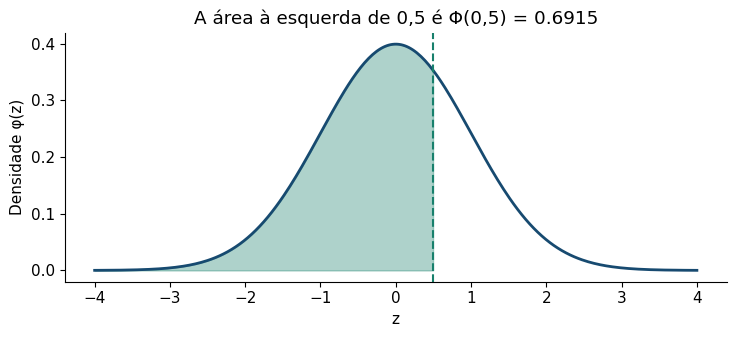

In [ ]:
indices = np.array([-2, -1, 0, 1, 2])
display(pd.DataFrame({"Índice z": indices, "Probabilidade Φ(z)": norm.cdf(indices)}).round(4))

grade_z = np.linspace(-4, 4, 300)
z_exemplo = 0.5
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(grade_z, norm.pdf(grade_z), color="#174a70", linewidth=2)
ax.fill_between(grade_z, norm.pdf(grade_z), where=grade_z <= z_exemplo,
                color="#18806c", alpha=0.35)
ax.axvline(z_exemplo, color="#18806c", linestyle="--")
ax.set(xlabel="z", ylabel="Densidade φ(z)", title=f"A área à esquerda de 0,5 é Φ(0,5) = {norm.cdf(0.5):.4f}")
fig.tight_layout()
plt.show()

## 3. Estimando o probit

Usaremos máxima verossimilhança com contribuições $p_i^{Y_i}(1-p_i)^{1-Y_i}$, como no logit, substituindo a função logística por $\Phi(X_i'\beta)$.

O sinal de um coeficiente indica a direção da mudança na probabilidade, nesta especificação. Sua magnitude, porém, está na escala do índice latente. **Um coeficiente de 1,6 não representa 160 pontos percentuais.**

In [ ]:
def tabela_inferencia(resultado, nomes):
    return pd.DataFrame({
        "Coeficiente": np.asarray(resultado.params),
        "Erro padrão": np.asarray(resultado.bse),
        "z (H0: coef. = 0)": np.asarray(resultado.tvalues),
        "p-valor": np.asarray(resultado.pvalues),
    }, index=nomes)

In [ ]:
probit = sm.Probit(y, X).fit(disp=False)
logit = sm.Logit(y, X).fit(disp=False)
mpl = sm.OLS(y, X).fit()
display(tabela_inferencia(probit, X.columns).style.format("{:.4f}"))
print(f"Convergência: {probit.mle_retvals['converged']} | Log-verossimilhança: {probit.llf:.4f}")

Convergência: True | Log-verossimilhança: -12.8188


,Coeficiente,Erro padrão,z (H0: coef. = 0),p-valor
const,-7.4523,2.5425,-2.9311,0.0034
GPA,1.6258,0.6939,2.3431,0.0191
TUCE,0.0517,0.0839,0.6166,0.5375
PSI,1.4263,0.5950,2.3970,0.0165


Os resultados reproduzem a Tabela 15.13 por arredondamento. O coeficiente de GPA é aproximadamente 1,6258 no probit e 2,8261 no logit. Isso **não demonstra que a associação do logit seja maior**: os índices têm escalas diferentes, associadas às normalizações das distribuições. Vamos comparar probabilidades e efeitos marginais na mesma unidade.

A estatística z é coeficiente dividido pelo erro padrão, com referência normal assintótica. A consistência da máxima verossimilhança depende da especificação probabilística correta, de identificação e de condições usuais de amostragem; não implica ausência de viés em amostra finita. Assumir somente erro com média zero não basta para derivar a curva probit.

## 4. Efeitos marginais: voltando à unidade de probabilidade

### Regressores contínuos

Para uma pequena mudança em GPA, mantendo o resto constante, a inclinação local da probabilidade é:

$$\frac{\partial P(Y_i=1\mid X_i)}{\partial GPA_i}=\phi(X_i'\beta)\beta_{GPA}.$$

O coeficiente é multiplicado pela densidade avaliada no perfil do estudante. Portanto, o efeito varia entre perfis. O **efeito marginal médio (AME)** é a média dessas inclinações na amostra. Ele difere de calcular uma única inclinação no perfil das médias.

Para uma variação finita, como 0,5 ponto de GPA, podemos comparar duas probabilidades previstas diretamente. Multiplicar uma derivada pelo passo é uma aproximação local, que pode ser ruim para mudanças grandes.

### Regressores binários

Para PSI, a mudança de interesse é de 0 para 1. Calcularemos a diferença exata entre as duas probabilidades, conservando as demais características, e depois sua média:

$$\Delta_i=\Phi(X_i'\beta\text{ com }PSI=1)-\Phi(X_i'\beta\text{ com }PSI=0).$$

No pacote, `at="overall"` pede a média na amostra e `dummy=True` pede mudanças de 0 para 1 nas variáveis binárias. GPA e TUCE continuam sendo tratados por derivadas.

In [ ]:
efeitos_probit = probit.get_margeff(at="overall", method="dydx", dummy=True)
efeitos_logit = logit.get_margeff(at="overall", method="dydx", dummy=True)
nomes_efeitos = ["GPA", "TUCE", "PSI"]

comparacao_efeitos = pd.DataFrame({
    "MPL: coeficiente × 100": 100 * mpl.params[nomes_efeitos],
    "Logit: efeito médio × 100": 100 * efeitos_logit.margeff,
    "Probit: efeito médio × 100": 100 * efeitos_probit.margeff,
})
display(comparacao_efeitos.style.format("{:.2f}"))
print("GPA e TUCE: inclinações locais médias, em p.p. por unidade.")
print("PSI: diferença média de probabilidade entre 0 e 1, em p.p.")

GPA e TUCE: inclinações locais médias, em p.p. por unidade.
PSI: diferença média de probabilidade entre 0 e 1, em p.p.


,MPL: coeficiente × 100,Logit: efeito médio × 100,Probit: efeito médio × 100
GPA,46.39,36.26,36.08
TUCE,1.05,1.22,1.15
PSI,37.86,35.75,37.38


O efeito médio de PSI é aproximadamente 37,38 pontos percentuais no probit. Isso é a média de comparações para os perfis da amostra. Não precisamos dizer que todas as pessoas tenham essa mesma diferença.

Para GPA, o efeito médio é uma **taxa local** de aproximadamente 36,08 p.p. por unidade. Para obter a mudança exata entre GPA 2,8 e 3,3, usaremos as previsões.

In [ ]:
perfis = pd.DataFrame({"GPA": [2.8, 3.3, 3.3], "TUCE": [20, 20, 20], "PSI": [0, 0, 1]},
                      index=["A", "B", "C"])
Xp = sm.add_constant(perfis[regressores], has_constant="add")
comparacao_prob = perfis.copy()
comparacao_prob["MPL"] = mpl.predict(Xp)
comparacao_prob["Logit"] = logit.predict(Xp)
comparacao_prob["Probit"] = probit.predict(Xp)
display(comparacao_prob.style.format({"GPA": "{:.1f}", "MPL": "{:.2%}", "Logit": "{:.2%}", "Probit": "{:.2%}"}))

,GPA,TUCE,PSI,MPL,Logit,Probit
A,2.8,20,0,1.07%,3.90%,3.11%
B,3.3,20,0,24.26%,14.28%,14.63%
C,3.3,20,1,62.12%,64.26%,64.57%


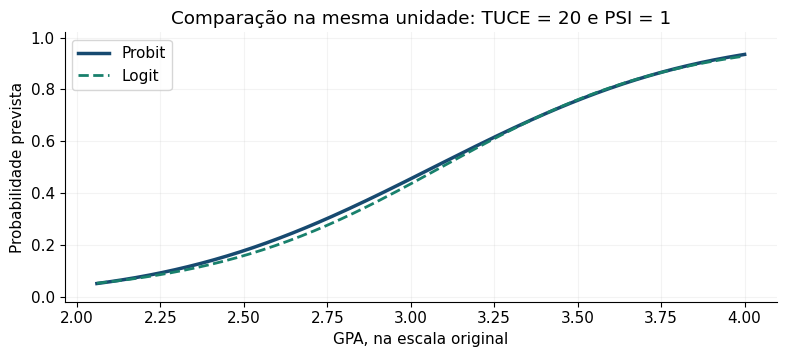

In [ ]:
grade_gpa = np.linspace(dados.GPA.min(), dados.GPA.max(), 150)
grade = pd.DataFrame({"GPA": grade_gpa, "TUCE": 20, "PSI": 1})
Xg = sm.add_constant(grade[regressores], has_constant="add")
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.plot(grade_gpa, probit.predict(Xg), color="#174a70", linewidth=2.5, label="Probit")
ax.plot(grade_gpa, logit.predict(Xg), color="#18806c", linewidth=2, linestyle="--", label="Logit")
ax.set(xlabel="GPA, na escala original", ylabel="Probabilidade prevista",
       title="Comparação na mesma unidade: TUCE = 20 e PSI = 1", ylim=(-0.02, 1.02))
ax.legend()
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

## 5. Incerteza e qualidade do ajuste · 42–50 min

No probit corretamente especificado, a verossimilhança Bernoulli já contempla a variância $p_i(1-p_i)$. Podemos comparar sua matriz usual com uma sanduíche HC0. A mudança afeta a incerteza estimada, preservando os coeficientes e as probabilidades. Não resolve endogeneidade nem torna correta uma função de probabilidade inadequada.

Os erros padrão dos efeitos marginais também podem ser calculados a partir da matriz dos coeficientes, pelo método delta. O pacote faz esse cálculo, incluindo a mudança discreta para a dummy.

In [ ]:
probit_robusto = sm.Probit(y, X).fit(disp=False, cov_type="HC0")
comparacao_cov = pd.concat({
    "Usual da verossimilhança": tabela_inferencia(probit, X.columns),
    "Sanduíche HC0": tabela_inferencia(probit_robusto, X.columns),
}, names=["Matriz", "Parâmetro"])
display(comparacao_cov.style.format("{:.4f}"))

efeitos_probit_hc0 = probit_robusto.get_margeff(at="overall", method="dydx", dummy=True)
tabela_ame_ep = pd.DataFrame({
    "Efeito médio": efeitos_probit.margeff,
    "EP usual do efeito": efeitos_probit.margeff_se,
    "EP HC0 do efeito": efeitos_probit_hc0.margeff_se,
}, index=nomes_efeitos)
display(tabela_ame_ep.style.format("{:.4f}"))

,Efeito médio,EP usual do efeito,EP HC0 do efeito
GPA,0.3608,0.1134,0.1013
TUCE,0.0115,0.0184,0.0150
PSI,0.3738,0.1400,0.1469


O capítulo também discute o *count R²*: a proporção de classificações corretas quando usamos, por exemplo, corte de 0,5. Vamos calculá-la na amostra usada na estimação. Ela não equivale ao R² de MQO nem ao pseudo R² da verossimilhança. Acerto dentro da amostra não prova boa previsão fora dela, especificação correta ou causalidade.

In [ ]:
ajuste = pd.DataFrame({
    "Fração de acertos na amostra (corte 0,5)": [
        np.mean((modelo.predict(X) >= 0.5).astype(int) == y)
        for modelo in [mpl, logit, probit]
    ]
}, index=["MPL", "Logit", "Probit"])
display(ajuste.style.format("{:.2%}"))

,"Fração de acertos na amostra (corte 0,5)"
MPL,81.25%
Logit,81.25%
Probit,81.25%


## 6. Exercício prático

**Nome:** escreva aqui.

### A. Uma mudança finita no GPA

Preencha GPA inicial 2,8 e GPA final 3,3; mantenha TUCE = 20 e PSI = 0. Calcule a diferença exata de probabilidade. Ela equivale ao coeficiente probit multiplicado por 0,5?

In [ ]:
gpa_inicial = None
gpa_final = None
if gpa_inicial is None or gpa_final is None:
    print("Preencha os dois valores de GPA.")
else:
    pe = pd.DataFrame({"GPA": [gpa_inicial, gpa_final], "TUCE": [20, 20], "PSI": [0, 0]})
    Xe = sm.add_constant(pe[regressores], has_constant="add")
    probs = probit.predict(Xe)
    print(f"Probabilidades: {100*probs.iloc[0]:.2f}% e {100*probs.iloc[1]:.2f}%")
    print(f"Diferença exata: {100*(probs.iloc[1]-probs.iloc[0]):.2f} p.p.")

Preencha os dois valores de GPA.


**Sua resposta — A:** Explique por que o coeficiente do índice não é uma mudança direta na probabilidade.

> Escreva aqui.

### B. Uma dummy para dois perfis

Digite GPA baixo 2,8 e GPA alto 3,3. Para cada um, mantenha TUCE = 20 e compare PSI = 1 com PSI = 0. A diferença é constante como no MPL desta aplicação?

In [ ]:
gpa_baixo = None
gpa_alto = None
if gpa_baixo is None or gpa_alto is None:
    print("Preencha os dois perfis de GPA.")
else:
    pe = pd.DataFrame({"GPA": [gpa_baixo, gpa_alto], "TUCE": [20, 20], "PSI": [0, 0]})
    X0 = sm.add_constant(pe[regressores], has_constant="add")
    X1 = X0.copy()
    X1["PSI"] = 1
    delta = probit.predict(X1) - probit.predict(X0)
    display(pd.DataFrame({"GPA": [gpa_baixo, gpa_alto], "Diferença de PSI (p.p.)": 100*delta}).round(4))

Preencha os dois perfis de GPA.


**Sua resposta — B:** Compare as diferenças entre os perfis e com o efeito médio de PSI.

> Escreva aqui.

### C. Comparando as escalas

Usando as tabelas, explique por que os coeficientes de GPA são diferentes no logit e no probit, embora seus efeitos marginais médios sejam próximos. A mudança para HC0 altera esses efeitos estimados ou apenas sua incerteza?

**Sua resposta — C:** Compare coeficientes, efeitos na probabilidade e erros padrão, usando as unidades corretas.

> Escreva aqui.

## 7. Fechamento

Para comparar MPL, logit e probit, use a mesma variável dependente, a mesma amostra e os mesmos regressores. Compare probabilidades e efeitos na probabilidade. Para contínuas, distinga inclinação local e mudança finita; para dummies, use a mudança de 0 para 1.

Na próxima aula, a variável observada será um valor monetário com censura, e a variável latente terá outra função no modelo.